# IoT Network Intrusion Detection  

**Research question:** Does a hybrid supervised + anomaly-detection approach improve IoT network intrusion detection over its individual components?

**Dataset:** CICIoT2023 CSV flow records.

## Methodology
- Offline analysis of labelled network-flow records.
- Chunk-based ingestion and category-wise reservoir sampling for memory control.
- Binary labels from parent-folder names: benign = 0, attack = 1.
- **Group-based splitting by source CSV** so rows from one CSV cannot cross between fit, calibration, and test partitions.
- Random Forest, benign-only Isolation Forest, and OR-based hybrid fusion.
- Evaluation using precision, recall, F1, false-positive rate, ROC-AUC and PR-AUC.

## Important interpretation
The notebook trains on a category-capped sample, not all 46.7 million records. The sample is not prevalence-preserving. Group splitting reduces within-file leakage, but does not guarantee independence if multiple CSVs belong to the same underlying capture/session/device.

In [1]:
from pathlib import Path
from collections import defaultdict
import gc, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score, average_precision_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
CHUNK_SIZE = 100_000
BENIGN_QUOTA = 200_000
ATTACK_QUOTA_PER_CATEGORY = 10_000

DATA_DIR = Path.cwd() / "data"
OUTPUT_DIR = Path.cwd() / "outputs"
MODEL_DIR = Path.cwd() / "models"
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(RANDOM_STATE)

print("Project:", Path.cwd())
print("Data folder exists:", DATA_DIR.exists())


Project: /Users/esha./IoT-Cybersecurity-Research
Data folder exists: True


In [2]:
CSV_PATHS = sorted(DATA_DIR.rglob("*.csv"))
if not CSV_PATHS:
    raise FileNotFoundError(f"No CSV files found under {DATA_DIR}")

print("CSV files:", len(CSV_PATHS))
for p in CSV_PATHS[:15]:
    print(p.relative_to(DATA_DIR), "| category:", p.parent.name)


CSV files: 309
CSV/Backdoor_Malware/Backdoor_Malware.pcap.csv | category: Backdoor_Malware
CSV/Benign_Final/BenignTraffic.pcap.csv | category: Benign_Final
CSV/Benign_Final/BenignTraffic1.pcap.csv | category: Benign_Final
CSV/Benign_Final/BenignTraffic2.pcap.csv | category: Benign_Final
CSV/Benign_Final/BenignTraffic3.pcap.csv | category: Benign_Final
CSV/BrowserHijacking/BrowserHijacking.pcap.csv | category: BrowserHijacking
CSV/CommandInjection/CommandInjection.pcap.csv | category: CommandInjection
CSV/DDoS-ACK_Fragmentation/DDoS-ACK_Fragmentation.pcap.csv | category: DDoS-ACK_Fragmentation
CSV/DDoS-ACK_Fragmentation/DDoS-ACK_Fragmentation1.pcap.csv | category: DDoS-ACK_Fragmentation
CSV/DDoS-ACK_Fragmentation/DDoS-ACK_Fragmentation10.pcap.csv | category: DDoS-ACK_Fragmentation
CSV/DDoS-ACK_Fragmentation/DDoS-ACK_Fragmentation11.pcap.csv | category: DDoS-ACK_Fragmentation
CSV/DDoS-ACK_Fragmentation/DDoS-ACK_Fragmentation12.pcap.csv | category: DDoS-ACK_Fragmentation
CSV/DDoS-ACK_Frag

In [3]:
def reservoir_update(sample, seen, chunk, quota, rng):
    # Maintain a uniform sample of `quota` rows from all rows seen so far.
    n = len(chunk)
    total = seen + n
    if n == 0:
        return sample, total
    if sample is None:
        if n > quota:
            sample = chunk.sample(n=quota, random_state=int(rng.integers(2**31 - 1)))
        else:
            sample = chunk.copy()
        return sample.reset_index(drop=True), total
    if total <= quota:
        return pd.concat([sample, chunk], ignore_index=True), total

    old_n = int(rng.hypergeometric(seen, n, quota))
    new_n = quota - old_n
    old_part = sample.sample(n=old_n, random_state=int(rng.integers(2**31 - 1))) if old_n else sample.iloc[:0]
    new_part = chunk.sample(n=new_n, random_state=int(rng.integers(2**31 - 1))) if new_n else chunk.iloc[:0]
    return pd.concat([old_part, new_part], ignore_index=True).reset_index(drop=True), total


reservoirs = {}
seen_by_category = defaultdict(int)
reference_columns = None

for i, path in enumerate(CSV_PATHS, 1):
    category = path.parent.name
    quota = BENIGN_QUOTA if "benign" in category.lower() else ATTACK_QUOTA_PER_CATEGORY
    print(f"[{i}/{len(CSV_PATHS)}] {category}/{path.name}")

    for chunk in pd.read_csv(path, chunksize=CHUNK_SIZE, low_memory=False):
        chunk.columns = [str(c).strip() for c in chunk.columns]
        if reference_columns is None:
            reference_columns = list(chunk.columns)
        elif list(chunk.columns) != reference_columns:
            raise ValueError(f"Feature columns differ in {path}")

        # Keep source CSV as a group ID for leakage-resistant splitting.
        # This metadata is excluded from model features later.
        chunk["__source_file"] = str(path.relative_to(DATA_DIR))
        chunk = chunk.dropna(how="all")
        reservoirs[category], seen_by_category[category] = reservoir_update(
            reservoirs.get(category), seen_by_category[category],
            chunk, quota, rng
        )
        del chunk
        gc.collect()

parts = []
for category, frame in reservoirs.items():
    if frame is not None and len(frame):
        frame = frame.copy()
        frame["attack_category"] = category
        frame["target"] = 0 if "benign" in category.lower() else 1
        parts.append(frame)

if not parts:
    raise RuntimeError("No rows were sampled. Check the CSV folder layout.")

data = pd.concat(parts, ignore_index=True)
del parts, reservoirs
gc.collect()

print("\nObserved rows by category:")
for k, v in sorted(seen_by_category.items()):
    print(k, f"{v:,}")
print("\nSample shape:", data.shape)
display(data["attack_category"].value_counts())
display(data["target"].value_counts().rename(index={0:"Benign", 1:"Attack"}))
if data["target"].nunique() != 2:
    raise ValueError("Both benign and attack categories must be present.")

[1/309] Backdoor_Malware/Backdoor_Malware.pcap.csv
[2/309] Benign_Final/BenignTraffic.pcap.csv
[3/309] Benign_Final/BenignTraffic1.pcap.csv
[4/309] Benign_Final/BenignTraffic2.pcap.csv
[5/309] Benign_Final/BenignTraffic3.pcap.csv
[6/309] BrowserHijacking/BrowserHijacking.pcap.csv
[7/309] CommandInjection/CommandInjection.pcap.csv
[8/309] DDoS-ACK_Fragmentation/DDoS-ACK_Fragmentation.pcap.csv
[9/309] DDoS-ACK_Fragmentation/DDoS-ACK_Fragmentation1.pcap.csv
[10/309] DDoS-ACK_Fragmentation/DDoS-ACK_Fragmentation10.pcap.csv
[11/309] DDoS-ACK_Fragmentation/DDoS-ACK_Fragmentation11.pcap.csv
[12/309] DDoS-ACK_Fragmentation/DDoS-ACK_Fragmentation12.pcap.csv
[13/309] DDoS-ACK_Fragmentation/DDoS-ACK_Fragmentation2.pcap.csv
[14/309] DDoS-ACK_Fragmentation/DDoS-ACK_Fragmentation3.pcap.csv
[15/309] DDoS-ACK_Fragmentation/DDoS-ACK_Fragmentation4.pcap.csv
[16/309] DDoS-ACK_Fragmentation/DDoS-ACK_Fragmentation5.pcap.csv
[17/309] DDoS-ACK_Fragmentation/DDoS-ACK_Fragmentation6.pcap.csv
[18/309] DDoS-ACK_

attack_category
Benign_Final               200000
DDoS-ACK_Fragmentation      10000
DDoS-HTTP_Flood             10000
DDoS-ICMP_Flood             10000
DDoS-ICMP_Fragmentation     10000
DDoS-PSHACK_FLOOD           10000
DDoS-RSTFINFLOOD            10000
DDoS-SYN_Flood              10000
DDoS-SlowLoris              10000
DDoS-SynonymousIP_Flood     10000
DDoS-TCP_Flood              10000
DDoS-UDP_Flood              10000
DDoS-UDP_Fragmentation      10000
DNS_Spoofing                10000
DictionaryBruteForce        10000
DoS-HTTP_Flood              10000
DoS-SYN_Flood               10000
DoS-TCP_Flood               10000
DoS-UDP_Flood               10000
MITM-ArpSpoofing            10000
Mirai-greeth_flood          10000
Mirai-greip_flood           10000
Mirai-udpplain              10000
Recon-HostDiscovery         10000
Recon-OSScan                10000
Recon-PortScan              10000
VulnerabilityScan           10000
BrowserHijacking             5859
CommandInjection             540

target
Attack    287091
Benign    200000
Name: count, dtype: int64

In [4]:
# Prepare numeric features. Keep source-file and category metadata separately.
excluded = {"attack_category", "target", "__source_file"}
identifier_names = {
    "flow_id", "src_ip", "source_ip", "dst_ip", "destination_ip",
    "timestamp", "date", "src_port", "source_port", "dst_port", "destination_port"
}
feature_cols = [
    c for c in data.columns
    if c not in excluded and str(c).strip().lower() not in identifier_names
]

X = data[feature_cols].copy()
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna(axis=1, how="all")
constant_cols = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
X = X.drop(columns=constant_cols)

y = data["target"].astype("int8")
attack_category = data["attack_category"].copy()
groups = data["__source_file"].astype(str).copy()

if groups.nunique() < 3:
    raise ValueError("Group-based splitting requires at least three source CSV files in the sample.")

print("Feature matrix:", X.shape)
print("Distinct source CSV groups:", groups.nunique())
print("Dropped constant columns:", constant_cols)
print("Missing values:", int(X.isna().sum().sum()))
print("\nSource CSV groups per category:")
display(data.groupby("attack_category")["__source_file"].nunique().sort_values())

Feature matrix: (487091, 39)
Distinct source CSV groups: 309
Dropped constant columns: []
Missing values: 61

Source CSV groups per category:


attack_category
Backdoor_Malware            1
Uploading_Attack            1
SqlInjection                1
Recon-PortScan              1
Recon-PingSweep             1
Recon-OSScan                1
Recon-HostDiscovery         1
DictionaryBruteForce        1
VulnerabilityScan           1
DDoS-SlowLoris              1
DNS_Spoofing                1
XSS                         1
BrowserHijacking            1
CommandInjection            1
DDoS-HTTP_Flood             1
DoS-HTTP_Flood              2
MITM-ArpSpoofing            2
Benign_Final                4
DoS-SYN_Flood               8
DoS-TCP_Flood              11
DDoS-UDP_Fragmentation     13
DDoS-ACK_Fragmentation     13
DDoS-SynonymousIP_Flood    14
DDoS-RSTFINFLOOD           16
DDoS-SYN_Flood             16
DDoS-PSHACK_FLOOD          16
DoS-UDP_Flood              17
DDoS-TCP_Flood             18
DDoS-ICMP_Fragmentation    20
DDoS-UDP_Flood             21
Mirai-greip_flood          22
Mirai-udpplain             25
DDoS-ICMP_Flood         

## 5. Group-based fit, calibration, and test split

A row-wise random split can place records from the same source CSV in both training and test sets. If rows within a file share capture conditions or near-duplicate patterns, this can inflate evaluation scores.

This section uses `GroupShuffleSplit` with the source CSV path as the group identifier. All sampled rows from one CSV stay in one partition. Split proportions are approximate because each CSV can contribute a different number of sampled rows.

The code retries deterministic seeds until both binary classes occur in each partition. If there are too few independent source files, it stops rather than silently falling back to a row-wise split.

In [5]:
from sklearn.model_selection import GroupShuffleSplit

def make_group_split(X_part, y_part, group_part, test_size, start_seed, max_tries=200):
    # Find a deterministic group-disjoint split with both binary classes on each side.
    for seed in range(start_seed, start_seed + max_tries):
        splitter = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
        train_i, held_i = next(splitter.split(X_part, y_part, group_part))
        if y_part.iloc[train_i].nunique() == 2 and y_part.iloc[held_i].nunique() == 2:
            return train_i, held_i, seed
    raise ValueError(
        "Could not create a group-disjoint split containing both classes. "
        "There may be too few source CSV files for one or both classes. "
        "Inspect the source-file counts per category. Do not silently use a row-wise split."
    )

# Outer split: approximately 15% of source-file groups for final testing.
train_i, test_i, test_seed = make_group_split(
    X, y, groups, test_size=0.15, start_seed=RANDOM_STATE
)

X_train = X.iloc[train_i].copy()
y_train = y.iloc[train_i].copy()
cat_train = attack_category.iloc[train_i].copy()
groups_train = groups.iloc[train_i].copy()

X_test = X.iloc[test_i].copy()
y_test = y.iloc[test_i].copy()
cat_test = attack_category.iloc[test_i].copy()
groups_test = groups.iloc[test_i].copy()

# Inner split: approximately 17.65% of remaining groups (about 15% overall).
fit_i, cal_i, cal_seed = make_group_split(
    X_train, y_train, groups_train, test_size=0.1765, start_seed=test_seed + 1
)

X_fit = X_train.iloc[fit_i].copy()
y_fit = y_train.iloc[fit_i].copy()
cat_fit = cat_train.iloc[fit_i].copy()
groups_fit = groups_train.iloc[fit_i].copy()

X_cal = X_train.iloc[cal_i].copy()
y_cal = y_train.iloc[cal_i].copy()
cat_cal = cat_train.iloc[cal_i].copy()
groups_cal = groups_train.iloc[cal_i].copy()

fit_groups, cal_groups, test_groups = set(groups_fit), set(groups_cal), set(groups_test)
assert fit_groups.isdisjoint(cal_groups)
assert fit_groups.isdisjoint(test_groups)
assert cal_groups.isdisjoint(test_groups)

print("Fit:", X_fit.shape, "| source CSV groups:", len(fit_groups))
print("Calibration:", X_cal.shape, "| source CSV groups:", len(cal_groups))
print("Test:", X_test.shape, "| source CSV groups:", len(test_groups))
print("Seeds:", {"test": test_seed, "calibration": cal_seed})
print("Group overlap checks: PASSED")

for name, labels in [("Fit", y_fit), ("Calibration", y_cal), ("Test", y_test)]:
    print("\\n" + name + " class distribution:")
    display(labels.value_counts().rename(index={0: "Benign", 1: "Attack"}))

Fit: (254594, 39) | source CSV groups: 215
Calibration: (136431, 39) | source CSV groups: 47
Test: (96066, 39) | source CSV groups: 47
Seeds: {'test': 42, 'calibration': 45}
Group overlap checks: PASSED
\nFit class distribution:


target
Attack    200837
Benign     53757
Name: count, dtype: int64

\nCalibration class distribution:


target
Benign    89610
Attack    46821
Name: count, dtype: int64

\nTest class distribution:


target
Benign    56633
Attack    39433
Name: count, dtype: int64

In [6]:
rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=120, max_features="sqrt", min_samples_leaf=2,
        class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=2
    ))
])
rf.fit(X_fit, y_fit)
print("Random Forest trained.")


Random Forest trained.


In [7]:
# Isolation Forest is fitted ONLY on benign fit rows.
benign_fit = X_fit.loc[y_fit == 0]
if len(benign_fit) < 100:
    raise ValueError("Not enough benign training rows.")

if_imputer = SimpleImputer(strategy="median")
benign_fit_imp = if_imputer.fit_transform(benign_fit)
if_model = IsolationForest(
    n_estimators=120, max_samples="auto", contamination="auto",
    random_state=RANDOM_STATE, n_jobs=2
)
if_model.fit(benign_fit_imp)

benign_cal = X_cal.loc[y_cal == 0]
benign_cal_scores = -if_model.decision_function(if_imputer.transform(benign_cal))
TARGET_CALIBRATION_FPR = 0.05
if_threshold = float(np.quantile(benign_cal_scores, 1 - TARGET_CALIBRATION_FPR))
print("Benign fit rows:", len(benign_fit))
print("Anomaly threshold:", if_threshold)


Benign fit rows: 53757
Anomaly threshold: 0.04281648010791373


In [8]:
rf_pred = rf.predict(X_test).astype("int8")
rf_prob = rf.predict_proba(X_test)[:, 1]
X_test_imp = if_imputer.transform(X_test)
anomaly_scores = -if_model.decision_function(X_test_imp)
if_pred = (anomaly_scores >= if_threshold).astype("int8")
hybrid_pred = np.logical_or(rf_pred == 1, if_pred == 1).astype("int8")

def metrics_row(name, truth, pred, prob=None):
    cm = confusion_matrix(truth, pred, labels=[0, 1])
    fpr = cm[0, 1] / max(1, cm[0].sum())
    return {
        "Model": name,
        "Accuracy": accuracy_score(truth, pred),
        "Precision": precision_score(truth, pred, zero_division=0),
        "Recall": recall_score(truth, pred, zero_division=0),
        "F1": f1_score(truth, pred, zero_division=0),
        "FPR": fpr,
        "ROC_AUC": roc_auc_score(truth, prob) if prob is not None else np.nan,
        "PR_AUC": average_precision_score(truth, prob) if prob is not None else np.nan
    }

metrics = pd.DataFrame([
    metrics_row("Random Forest", y_test, rf_pred, rf_prob),
    metrics_row("Isolation Forest", y_test, if_pred),
    metrics_row("Hybrid OR", y_test, hybrid_pred)
])
display(metrics.round(4))
metrics.to_csv(OUTPUT_DIR / "model_metrics.csv", index=False)


,Model,Accuracy,Precision,Recall,F1,FPR,ROC_AUC,PR_AUC
0,Random Forest,0.8863,0.8576,0.8668,0.8622,0.1002,0.9559,0.9479
1,Isolation Forest,0.7651,0.9609,0.4459,0.6091,0.0126,NaN,NaN
2,Hybrid OR,0.8843,0.8526,0.8681,0.8603,0.1045,NaN,NaN


\n Random Forest
[[50958  5675]
 [ 5251 34182]]
              precision    recall  f1-score   support

      Benign       0.91      0.90      0.90     56633
      Attack       0.86      0.87      0.86     39433

    accuracy                           0.89     96066
   macro avg       0.88      0.88      0.88     96066
weighted avg       0.89      0.89      0.89     96066



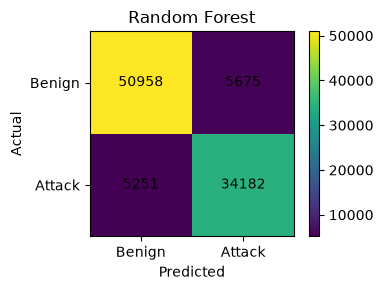

\n Isolation Forest
[[55918   715]
 [21851 17582]]
              precision    recall  f1-score   support

      Benign       0.72      0.99      0.83     56633
      Attack       0.96      0.45      0.61     39433

    accuracy                           0.77     96066
   macro avg       0.84      0.72      0.72     96066
weighted avg       0.82      0.77      0.74     96066



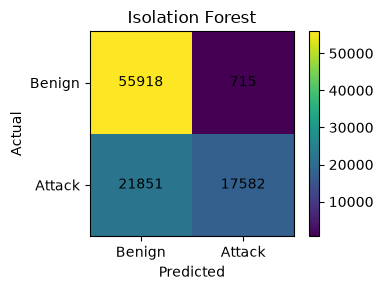

\n Hybrid OR
[[50717  5916]
 [ 5203 34230]]
              precision    recall  f1-score   support

      Benign       0.91      0.90      0.90     56633
      Attack       0.85      0.87      0.86     39433

    accuracy                           0.88     96066
   macro avg       0.88      0.88      0.88     96066
weighted avg       0.88      0.88      0.88     96066



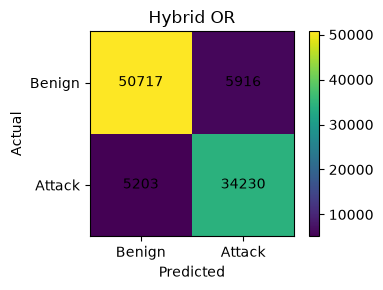

In [9]:
for name, pred in [("Random Forest", rf_pred), ("Isolation Forest", if_pred), ("Hybrid OR", hybrid_pred)]:
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    print("\\n", name)
    print(cm)
    print(classification_report(y_test, pred, target_names=["Benign", "Attack"], zero_division=0))
    fig, ax = plt.subplots(figsize=(4, 3))
    im = ax.imshow(cm)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0, 1], ["Benign", "Attack"])
    ax.set_yticks([0, 1], ["Benign", "Attack"])
    for (r, c), value in np.ndenumerate(cm):
        ax.text(c, r, str(value), ha="center", va="center")
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()


In [10]:
# Permutation importance on at most 3,000 held-out rows to bound runtime.
n_perm = min(3000, len(X_test))
X_perm = X_test.sample(n=n_perm, random_state=RANDOM_STATE)
y_perm = y_test.loc[X_perm.index]
perm = permutation_importance(
    rf, X_perm, y_perm, n_repeats=3, random_state=RANDOM_STATE,
    scoring="f1", n_jobs=2
)
importance = pd.DataFrame({
    "feature": X_perm.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)
display(importance.head(20))
importance.to_csv(OUTPUT_DIR / "permutation_feature_importance.csv", index=False)


/opt/anaconda3/envs/websec-research/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,feature,importance_mean,importance_std
16,HTTPS,0.114597,0.002551
32,Max,0.099671,0.002531
37,Number,0.096860,0.001688
2,Time_To_Live,0.061148,0.000633
0,Header_Length,0.059913,0.001543
36,IAT,0.024459,0.001996
30,Tot sum,0.019640,0.001601
3,Rate,0.018553,0.001235
7,psh_flag_number,0.017942,0.002401
11,ack_count,0.009611,0.001727


In [11]:
# Per-attack-category recall on the held-out test set.
test_report = pd.DataFrame({
    "category": cat_test,
    "actual": y_test,
    "rf_prediction": rf_pred,
    "hybrid_prediction": hybrid_pred
})
attack_test = test_report[test_report["actual"] == 1]
category_metrics = attack_test.groupby("category").apply(
    lambda g: pd.Series({
        "test_rows": len(g),
        "RF_recall": (g["rf_prediction"] == 1).mean(),
        "Hybrid_recall": (g["hybrid_prediction"] == 1).mean()
    })
)
display(category_metrics.sort_values("test_rows", ascending=False))
category_metrics.to_csv(OUTPUT_DIR / "attack_category_recall.csv")


,test_rows,RF_recall,Hybrid_recall
category,,,
DictionaryBruteForce,10000.0,0.658600,0.660500
BrowserHijacking,5859.0,0.721113,0.725380
DDoS-SYN_Flood,2601.0,1.000000,1.000000
DDoS-ICMP_Flood,2225.0,1.000000,1.000000
DDoS-PSHACK_FLOOD,2183.0,1.000000,1.000000
Mirai-udpplain,2037.0,1.000000,1.000000
DDoS-UDP_Flood,1955.0,1.000000,1.000000
DDoS-ACK_Fragmentation,1567.0,1.000000,1.000000
DDoS-UDP_Fragmentation,1544.0,1.000000,1.000000


In [12]:
# Example risk prioritization score (research demonstration, not production).
a_min, a_max = anomaly_scores.min(), anomaly_scores.max()
a_norm = (anomaly_scores - a_min) / (a_max - a_min) if a_max > a_min else np.zeros_like(anomaly_scores)
risk_score = 100 * (0.6 * rf_prob + 0.4 * a_norm)

risk = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "rf_attack_probability": rf_prob,
    "anomaly_score": anomaly_scores,
    "risk_score": risk_score,
    "hybrid_prediction": hybrid_pred
}, index=y_test.index)
risk["risk_level"] = pd.cut(risk["risk_score"], [-0.01, 40, 70, 100],
                            labels=["Low", "Medium", "High"])
display(risk.sort_values("risk_score", ascending=False).head(20))
risk.to_csv(OUTPUT_DIR / "test_risk_scores.csv", index=False)


,actual,rf_attack_probability,anomaly_score,risk_score,hybrid_prediction,risk_level
245636,1,0.987037,0.178772,98.338364,1,High
249922,1,1.000000,0.166168,97.664948,1,High
251215,1,0.970392,0.180027,97.484147,1,High
333342,1,1.000000,0.162211,97.209251,1,High
245444,1,0.993433,0.165343,97.175911,1,High
245283,1,1.000000,0.159748,96.925625,1,High
351611,1,0.977750,0.168595,96.609281,1,High
251501,1,1.000000,0.156902,96.598012,1,High
246079,1,1.000000,0.156212,96.518571,1,High
344942,1,0.962864,0.173079,96.232423,1,High


In [13]:
joblib.dump(rf, MODEL_DIR / "random_forest_pipeline.joblib")
joblib.dump(if_imputer, MODEL_DIR / "isolation_forest_imputer.joblib")
joblib.dump(if_model, MODEL_DIR / "isolation_forest.joblib")

metadata = {
    "dataset": "CICIoT2023",
    "sampling": "uniform reservoir sample within each parent-folder category",
    "benign_quota": BENIGN_QUOTA,
    "attack_quota_per_category": ATTACK_QUOTA_PER_CATEGORY,
    "chunk_size": CHUNK_SIZE,
    "sample_rows": int(len(data)),
    "random_state": RANDOM_STATE,
    "split": {"method": "GroupShuffleSplit by source CSV", "approximate_fit": 0.70, "approximate_calibration": 0.15, "approximate_test": 0.15, "fit_groups": len(fit_groups), "calibration_groups": len(cal_groups), "test_groups": len(test_groups), "test_seed": test_seed, "calibration_seed": cal_seed},
    "labels": {"benign": 0, "attack": 1},
    "categories": sorted(data["attack_category"].unique().tolist()),
    "features": X.columns.tolist()
}
with open(OUTPUT_DIR / "experiment_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

# Parquet keeps the sample smaller than CSV in most cases.
data.to_csv(OUTPUT_DIR / "sampled_experiment_data.csv", index=False)

print("Models saved in:", MODEL_DIR.resolve())
print("Results saved in:", OUTPUT_DIR.resolve())

Models saved in: /Users/esha./IoT-Cybersecurity-Research/models
Results saved in: /Users/esha./IoT-Cybersecurity-Research/outputs


## Methodological notes and limitations

- The full CICIoT2023 dataset remains unchanged on disk. Model training uses the category-capped sample.
- Sampling is uniform within each folder category with a maximum quota per category; it is **not prevalence-preserving**.
- Benign rows have target `0`; non-benign folders have target `1`.
- `attack_category` and `__source_file` are retained for reporting and grouping but excluded from model features.
- Fit, calibration, and test partitions are group-disjoint by source CSV. Ratios are approximate because source files contribute different numbers of sampled rows.
- Group splitting reduces leakage between rows from the same CSV, but does not guarantee independence if separate CSVs originate from the same underlying capture/session/device.
- The Isolation Forest is trained only on benign fit rows; its threshold is calibrated on benign calibration rows.
- The hybrid OR rule may increase recall and false positives.
- Report sampling quotas, group split methodology, random seeds, feature list, and limitations in the paper.